In [ ]:
!pip install geobr

In [ ]:
import pandas as pd
import geobr
import geopandas as gpd
import matplotlib.pyplot as plt

micro = geobr.read_micro_region(
    year=2020,
    simplified=True
)

micro['chave_join'] = micro['name_micro'].str.strip().str.casefold()
micro.head()

c:\Users\okubo\OneDrive\Documentos\PCD2\.venv\lib\site-packages\urllib3\connectionpool.py:1110: InsecureRequestWarning: Unverified HTTPS request is being made to host 'github.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
c:\Users\okubo\OneDrive\Documentos\PCD2\.venv\lib\site-packages\urllib3\connectionpool.py:1110: InsecureRequestWarning: Unverified HTTPS request is being made to host 'release-assets.githubusercontent.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
microregions_2020_simplified.parquet: 100%|██████████| 7.91M/7.91M [00:00<00:00, 30.2MB/s]


,code_micro,name_micro,code_state,abbrev_state,name_state,code_region,name_region,year,geometry,chave_join
0,11001.0,Porto Velho,11.0,RO,Rondônia,1.0,Norte,2020.0,"POLYGON ((-63.10218 -9.47892, -63.07806 -9.508...",porto velho
1,11002.0,Guajará-Mirim,11.0,RO,Rondônia,1.0,Norte,2020.0,"POLYGON ((-64.60819 -12.21637, -64.58383 -12.2...",guajará-mirim
2,11003.0,Ariquemes,11.0,RO,Rondônia,1.0,Norte,2020.0,"POLYGON ((-63.07806 -9.50802, -63.10218 -9.478...",ariquemes
3,11004.0,Ji-Paraná,11.0,RO,Rondônia,1.0,Norte,2020.0,"POLYGON ((-62.66998 -10.28828, -62.67077 -10.2...",ji-paraná
4,11005.0,Alvorada d'Oeste,11.0,RO,Rondônia,1.0,Norte,2020.0,"POLYGON ((-63.60307 -11.60143, -63.61343 -11.6...",alvorada d'oeste


In [ ]:
path = "../data/raw/dadosSidra2005_2024.csv"

# Acha automaticamente onde a tabela termina, procurando a linha "Fonte:"
# que o SIDRA/IBGE sempre coloca logo após os dados
with open(path, encoding='utf-8-sig') as f:
    linhas = f.readlines()

linha_fonte = next(i for i, l in enumerate(linhas) if l.strip().startswith('"Fonte:'))
n_dados = linha_fonte - 3   # linhas 0-1 = título/cabeçalho truncado, linha 2 = header real

df = pd.read_csv(
    path,
    sep=';',
    encoding='utf-8-sig',   # o arquivo tem BOM UTF-8
    skiprows=2,             # pula título + cabeçalho truncado
    nrows=n_dados,          # lê só até a última linha antes de "Fonte:"
    quotechar='"',
)

# opcional: converter colunas numéricas (vírgula decimal, "-" para ausente)
# df['Área plantada - percentual do total geral'] = (
#     df['Área plantada - percentual do total geral']
#     .str.replace(',', '.', regex=False)
#     .replace('-', pd.NA)
#     .astype(float)
# )

# for col in ['Área plantada (Hectares)', 'Área colhida (Hectares)',
#             'Quantidade produzida (Toneladas)',
#             'Rendimento médio da produção (Quilogramas por Hectare)']:
#     df[col] = pd.to_numeric(df[col].astype(str).str.strip(), errors='coerce')

df["Microrregião Geográfica"] = df["Microrregião Geográfica"].str.replace(r"\s*\([A-Z]{2}\)$", "", regex=True)
df['chave_join'] = df['Microrregião Geográfica'].str.strip().str.casefold()

df.head()

,Microrregião Geográfica,Ano,#,Produto das lavouras temporárias,Área plantada (Hectares),Área plantada - percentual do total geral,Área colhida (Hectares),Área colhida - percentual do total geral,Quantidade produzida (Toneladas),Rendimento médio da produção (Quilogramas por Hectare),chave_join
0,Porto Velho,2005,1,Soja (em grão),455,"1,27",455,"1,27",1365,3000,porto velho
1,Porto Velho,2006,1,Soja (em grão),710,"1,97",710,"1,97",1706,2402,porto velho
2,Porto Velho,2007,1,Soja (em grão),710,"1,94",680,"1,89",1768,2600,porto velho
3,Porto Velho,2008,1,Soja (em grão),380,"1,04",380,"1,07",984,2589,porto velho
4,Porto Velho,2009,1,Soja (em grão),300,"0,81",300,"0,81",720,2400,porto velho


In [4]:
producao_soja_com_micro = micro.merge(
    df,
    on='chave_join',
    how='outer'
).rename(columns={'Ano': 'ano'})

producao_soja_com_micro[producao_soja_com_micro['code_micro'].isna()]

,code_micro,name_micro,code_state,abbrev_state,name_state,code_region,name_region,year,geometry,chave_join,Microrregião Geográfica,ano,#,Produto das lavouras temporárias,Área plantada (Hectares),Área plantada - percentual do total geral,Área colhida (Hectares),Área colhida - percentual do total geral,Quantidade produzida (Toneladas),Rendimento médio da produção (Quilogramas por Hectare)


In [5]:
producao_soja_com_micro[producao_soja_com_micro['Microrregião Geográfica'].isna()]

,code_micro,name_micro,code_state,abbrev_state,name_state,code_region,name_region,year,geometry,chave_join,Microrregião Geográfica,ano,#,Produto das lavouras temporárias,Área plantada (Hectares),Área plantada - percentual do total geral,Área colhida (Hectares),Área colhida - percentual do total geral,Quantidade produzida (Toneladas),Rendimento médio da produção (Quilogramas por Hectare)


In [8]:
path = "../data/processed/clima_diario_agg.parquet"

diario = pd.read_parquet(path)
diario.head()

,codigo_estacao,uf,estacao,latitude,longitude,data,prec_total,temp_media,temp_max,temp_min,umid_media,radiacao_total,vento_medio,n_horas_validas,amplitude_termica,dia_seco,gdd
0,A001,DF,BRASILIA,-15.789444,-47.925833,2005-01-01,0.4,21.204167,26.0,19.1,81.541667,8642.0,1.533333,24,6.9,True,12.55
1,A001,DF,BRASILIA,-15.789444,-47.925833,2005-01-02,8.8,20.800000,26.9,18.3,83.208333,3868.0,1.979167,24,8.6,False,12.60
2,A001,DF,BRASILIA,-15.789444,-47.925833,2005-01-03,10.8,19.833333,24.1,17.8,85.875000,6146.0,3.091667,24,6.3,False,10.95
3,A001,DF,BRASILIA,-15.789444,-47.925833,2005-01-04,16.2,20.595833,27.5,17.4,84.333333,6850.0,2.154167,24,10.1,False,12.45
4,A001,DF,BRASILIA,-15.789444,-47.925833,2005-01-05,15.8,20.804167,25.7,17.5,82.583333,2697.0,2.116667,24,8.2,False,11.60


In [ ]:
from shapely.geometry import Point

microrregioes = geobr.read_micro_region(year=2020)  # ajuste o ano se necessário

print(microrregioes.crs)          # confira o CRS de referência
print(microrregioes.columns.tolist())


# ============================================================
# CÉLULA 3 — Montar o GeoDataFrame das estações
# ============================================================
# Parte da tabela de estações únicas que você já extrai no pipeline
# climático (codigo_estacao, uf, estacao, latitude, longitude).
# Se ainda não tiver essa tabela separada, extraia do diario_unido:
estacoes = diario[['codigo_estacao', 'estacao', 'uf', 'latitude', 'longitude']].drop_duplicates()

# Uma mesma estação pode ter coordenadas levemente diferentes entre
# arquivos de anos diferentes (deriva de metadado no cabeçalho do
# INMET). Isso gera linhas "duplicadas" que na verdade são a mesma
# estação física -- se não resolver aqui, ela acaba contando duas vezes
# na agregação climática mais adiante, além de poder quebrar joins que
# dependem de codigo_estacao ser único.
duplicadas = estacoes[estacoes.duplicated('codigo_estacao', keep=False)]
if len(duplicadas) > 0:
    print(f"{duplicadas['codigo_estacao'].nunique()} estação(ões) com coordenadas "
          "divergentes entre arquivos -- usando a mediana das coordenadas:")
    print(duplicadas.sort_values('codigo_estacao'))

estacoes = (estacoes.groupby('codigo_estacao', as_index=False)
            .agg(estacao=('estacao', 'first'), uf=('uf', 'first'),
                 latitude=('latitude', 'median'), longitude=('longitude', 'median')))

geometria_estacoes = [Point(lon, lat) for lon, lat in zip(estacoes['longitude'], estacoes['latitude'])]
# Point(x, y) = Point(longitude, latitude) -- shapely usa (x, y), não (lat, lon).
# Inverter essa ordem é um erro clássico e silencioso (o ponto cai no
# hemisfério/quadrante errado sem lançar erro nenhum).

estacoes_geo = gpd.GeoDataFrame(estacoes, geometry=geometria_estacoes, crs="EPSG:4326")
# EPSG:4326 = WGS84, o sistema padrão de lat/lon (graus decimais).
# É o mesmo sistema que o INMET usa para as coordenadas do cabeçalho.

# Garantir que as estações estão no MESMO CRS da malha de microrregiões
# antes de comparar geometrias -- CRS diferente dá resultado errado sem
# lançar erro.
estacoes_geo = estacoes_geo.to_crs(microrregioes.crs)


# ============================================================
# CÉLULA 4 — Join espacial (point-in-polygon)
# ============================================================
estacoes_com_micro = gpd.sjoin(
    estacoes_geo,
    microrregioes[['code_micro', 'name_micro', 'geometry']],
    how='left',
    predicate='within',   # "all versão recente do geopandas usa predicate; versões antigas usam op"
)

print(f"{estacoes_com_micro['code_micro'].isna().sum()} estação(ões) sem microrregião correspondente.")
print(estacoes_com_micro[estacoes_com_micro['code_micro'].isna()][['codigo_estacao', 'estacao', 'uf', 'latitude', 'longitude']])


# ============================================================
# CÉLULA 5 — Fallback: estações que não caíram em nenhum polígono
# ============================================================
# Acontece por 2 motivos principais: (a) coordenada do cabeçalho do
# INMET com erro de digitação/exportação, ou (b) ponto exatamente
# sobre a fronteira/costa, perdido por imprecisão de arredondamento.
# Para essas, associamos à microrregião cujo polígono está mais
# próximo (em vez de descartar a estação inteira).

sem_correspondencia = estacoes_com_micro[estacoes_com_micro['code_micro'].isna()].copy()

# Distância acima da qual a "estação/microrregião mais próxima" não tem
# mais sentido físico como representante (ex: uma estação da Antártica
# ou de um arquipélago oceânico distante não deveria herdar o clima de
# uma microrregião continental a milhares de km).
DISTANCIA_MAXIMA_KM = 150

if len(sem_correspondencia) > 0:
    microrregioes_metros = microrregioes.to_crs(epsg=5880)
    sem_correspondencia_metros = sem_correspondencia[['codigo_estacao', 'geometry']].to_crs(epsg=5880)

    mais_proximo = gpd.sjoin_nearest(
        sem_correspondencia_metros,
        microrregioes_metros[['code_micro', 'name_micro', 'geometry']],
        how='left',
        distance_col='distancia_m',
    )
    mais_proximo['distancia_km'] = mais_proximo['distancia_m'] / 1000

    print("Distância (km) até a microrregião mais próxima, para os casos sem correspondência direta:")
    print(mais_proximo[['codigo_estacao', 'name_micro', 'distancia_km']].round(1)
          .sort_values('distancia_km', ascending=False))

    # Só aceita o fallback dentro do limiar; acima disso, a estação fica
    # de fora do mapa (não faz sentido forçar uma atribuição a milhares
    # de km de distância -- ex: estação da Antártica, arquipélagos).
    dentro_do_limiar = mais_proximo[mais_proximo['distancia_km'] <= DISTANCIA_MAXIMA_KM]
    excluidas = mais_proximo[mais_proximo['distancia_km'] > DISTANCIA_MAXIMA_KM]

    if len(excluidas) > 0:
        print(f"\n{len(excluidas)} estação(ões) excluída(s) por estarem a mais de "
              f"{DISTANCIA_MAXIMA_KM}km de qualquer microrregião (provavelmente fora do "
              "território continental, ex: Antártica, arquipélagos oceânicos):")
        print(excluidas[['codigo_estacao', 'name_micro', 'distancia_km']].round(1))

    # merge (não .loc por índice) -- funciona mesmo se codigo_estacao tiver
    # duplicatas na tabela de estações, sem quebrar por índice ambíguo.
    # Isso também é o sinal para investigar a duplicata na origem: a
    # mesma estação com coordenadas levemente diferentes entre arquivos
    # de anos diferentes (deriva de metadado), o que merece dedupe
    # anterior na construção de `estacoes` se possível.
    substituicoes = (dentro_do_limiar[['codigo_estacao', 'code_micro', 'name_micro']]
                      .drop_duplicates('codigo_estacao')
                      .rename(columns={'code_micro': 'code_micro_sub', 'name_micro': 'name_micro_sub'}))

    estacoes_com_micro = estacoes_com_micro.merge(substituicoes, on='codigo_estacao', how='left')
    estacoes_com_micro['code_micro'] = estacoes_com_micro['code_micro'].fillna(estacoes_com_micro['code_micro_sub'])
    estacoes_com_micro['name_micro'] = estacoes_com_micro['name_micro'].fillna(estacoes_com_micro['name_micro_sub'])
    estacoes_com_micro = estacoes_com_micro.drop(columns=['code_micro_sub', 'name_micro_sub'])

    print(f"\n{estacoes_com_micro['code_micro'].isna().sum()} estação(ões) ainda sem "
          "correspondência após fallback (excluídas do mapa final).")


# ============================================================
# CÉLULA 6 — Tabela final: estação -> microrregião
# ============================================================
mapa_estacao_micro = estacoes_com_micro[['codigo_estacao', 'estacao', 'uf', 'code_micro', 'name_micro']]
print(mapa_estacao_micro)

# A partir daqui, junte esse mapa de volta no diario (ou no agregado por
# safra) e agregue por code_micro em vez de uf:
#
# diario_com_micro = diario.merge(mapa_estacao_micro[['codigo_estacao', 'code_micro']],
#                                  on='codigo_estacao', how='left')
# clima_micro_safra = diario_com_micro.groupby(['code_micro', 'safra']).agg(...)


# ============================================================
# CÉLULA 7 — Microrregiões que não receberam NENHUMA estação
# ============================================================
# O sjoin só rotula estações que caem dentro de algum polígono. Uma
# microrregião sem nenhuma estação dentro dela simplesmente não aparece
# depois do groupby -- não vira NaN, ela desaparece silenciosamente.
# Aqui invertemos a lógica: para essas microrregiões vazias, perguntamos
# "qual é a estação mais próxima do MEU centro?", em vez de "qual
# estação cai dentro de mim" (que já deu zero).

microrregioes_com_estacao = set(estacoes_com_micro['code_micro'].dropna())
todas_microrregioes = set(microrregioes['code_micro'])
microrregioes_vazias = todas_microrregioes - microrregioes_com_estacao

print(f"{len(microrregioes_vazias)} de {len(todas_microrregioes)} microrregiões "
      f"não têm nenhuma estação dentro delas.")

if microrregioes_vazias:
    micro_vazias_gdf = microrregioes[microrregioes['code_micro'].isin(microrregioes_vazias)].copy()

    # Centróide de cada microrregião vazia, em CRS métrico para a
    # distância fazer sentido fisicamente (não em graus de lat/lon)
    micro_vazias_metros = micro_vazias_gdf.to_crs(epsg=5880)
    micro_vazias_metros['geometry'] = micro_vazias_metros.centroid

    estacoes_metros = estacoes_geo.to_crs(epsg=5880)

    estacao_substituta = gpd.sjoin_nearest(
        micro_vazias_metros[['code_micro', 'name_micro', 'geometry']],
        estacoes_metros[['codigo_estacao', 'estacao', 'geometry']],
        how='left',
        distance_col='distancia_m',
    )

    print("\nDistância (km) até a estação substituta, para as microrregiões sem estação própria:")
    print(estacao_substituta.assign(distancia_km=lambda d: (d['distancia_m']/1000).round(0))
          [['code_micro', 'name_micro', 'codigo_estacao', 'distancia_km']]
          .sort_values('distancia_km', ascending=False).head(15))

    # Mesmo limiar da Célula 5: acima disso, não faz sentido físico
    # emprestar o clima de uma estação tão distante.
    estacao_substituta['distancia_km'] = estacao_substituta['distancia_m'] / 1000
    longe_demais = estacao_substituta[estacao_substituta['distancia_km'] > DISTANCIA_MAXIMA_KM]
    if len(longe_demais) > 0:
        print(f"\n{len(longe_demais)} microrregião(ões) sem substituta dentro de "
              f"{DISTANCIA_MAXIMA_KM}km -- ficarão sem clima (não entrarão no merge final):")
        print(longe_demais[['code_micro', 'name_micro', 'distancia_km']].round(1))
    estacao_substituta = estacao_substituta[estacao_substituta['distancia_km'] <= DISTANCIA_MAXIMA_KM]

    # Anexa essas microrregiões "órfãs" na tabela final, apontando para
    # a estação substituta -- assim elas também entram na agregação
    orfas = estacao_substituta[['code_micro', 'name_micro', 'codigo_estacao']].copy()
    orfas['origem'] = 'substituta_por_centroide'
    mapa_estacao_micro['origem'] = 'dentro_do_poligono'
    mapa_estacao_micro_completo = pd.concat([mapa_estacao_micro, orfas], ignore_index=True)
else:
    mapa_estacao_micro_completo = mapa_estacao_micro.assign(origem='dentro_do_poligono')

print(f"\nCobertura final: {mapa_estacao_micro_completo['code_micro'].nunique()} "
      f"de {len(todas_microrregioes)} microrregiões com alguma estação (própria ou substituta).")

EPSG:4674
['code_micro', 'name_micro', 'code_state', 'abbrev_state', 'name_state', 'code_region', 'name_region', 'year', 'geometry']
548 estação(ões) com coordenadas divergentes entre arquivos -- usando a mediana das coordenadas:
        codigo_estacao              estacao  uf   latitude  longitude
0                 A001             BRASILIA  DF -15.789444 -47.925833
1827107           A001             BRASILIA  DF -15.789343 -47.925756
348               A002              GOIANIA  GO -16.642778 -49.220000
1828911           A002              GOIANIA  GO -16.642841 -49.220222
2429210           A002              GOIANIA  GO -16.642778 -49.220278
...                ...                  ...  ..        ...        ...
1660367           S715   RIBAS DO RIO PARDO  MS -20.466667 -53.763056
1660652           S716  SANTA RITA DO PARDO  MS -21.305833 -52.820278
1849115           S716  SANTA RITA DO PARDO  MS -21.305889 -52.820375
1849328           S717             SELVIRIA  MS -20.351444 -51.430222


C:\Users\okubo\AppData\Local\Temp\ipykernel_34020\1933992145.py:193: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mapa_estacao_micro['origem'] = 'dentro_do_poligono'


: 

In [4]:
import pandas as pd

path = "../data/raw/dadosSidra2005_2024.csv"

# Acha automaticamente onde a tabela termina, procurando a linha "Fonte:"
# que o SIDRA/IBGE sempre coloca logo após os dados
with open(path, encoding='utf-8-sig') as f:
    linhas = f.readlines()

linha_fonte = next(i for i, l in enumerate(linhas) if l.strip().startswith('"Fonte:'))
n_dados = linha_fonte - 3   # linhas 0-1 = título/cabeçalho truncado, linha 2 = header real

df = pd.read_csv(
    path,
    sep=';',
    encoding='utf-8-sig',   # o arquivo tem BOM UTF-8
    skiprows=2,             # pula título + cabeçalho truncado
    nrows=n_dados,          # lê só até a última linha antes de "Fonte:"
    quotechar='"',
) 

df.head()

,Microrregião Geográfica,Ano,#,Produto das lavouras temporárias,Área plantada (Hectares),Área plantada - percentual do total geral,Área colhida (Hectares),Área colhida - percentual do total geral,Quantidade produzida (Toneladas),Rendimento médio da produção (Quilogramas por Hectare)
0,Porto Velho (RO),2005,1,Soja (em grão),455,"1,27",455,"1,27",1365,3000
1,Porto Velho (RO),2006,1,Soja (em grão),710,"1,97",710,"1,97",1706,2402
2,Porto Velho (RO),2007,1,Soja (em grão),710,"1,94",680,"1,89",1768,2600
3,Porto Velho (RO),2008,1,Soja (em grão),380,"1,04",380,"1,07",984,2589
4,Porto Velho (RO),2009,1,Soja (em grão),300,"0,81",300,"0,81",720,2400


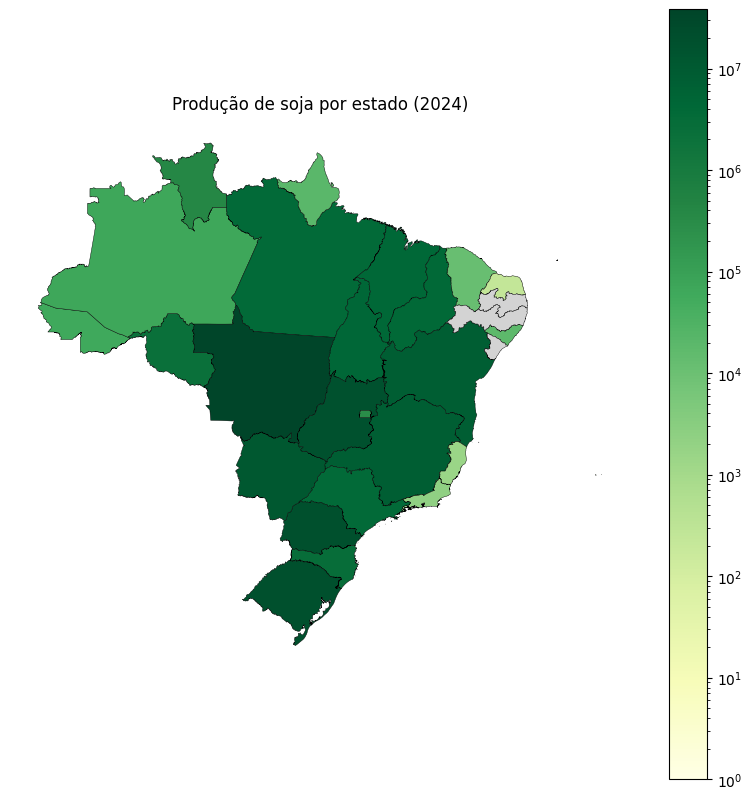

In [12]:
import geobr
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# 1. Geometrias dos estados
estados = geobr.read_state(year=2020)

# 2. Extrair a UF da coluna "Microrregião Geográfica" e agregar por estado
df['uf'] = df['Microrregião Geográfica'].str.extract(r'\((\w+)\)$')

cols_numericas = [
    'Área plantada (Hectares)',
    'Área colhida (Hectares)',
    'Quantidade produzida (Toneladas)',
]

for col in cols_numericas:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(',', '.').replace('-', pd.NA),
        errors='coerce'
    )

producao_uf = (
    df[df['Ano'] == 2024]
    .groupby('uf', as_index=False)[cols_numericas]
    .sum(min_count=1)  # importante: ver nota abaixo
)

producao_uf['Quantidade produzida (Toneladas)'] = pd.to_numeric(
    producao_uf['Quantidade produzida (Toneladas)'],
    errors='coerce'
)

producao_uf['Área colhida (Hectares)'] = pd.to_numeric(
    producao_uf['Área colhida (Hectares)'],
    errors='coerce'
)

# rendimento médio ponderado do estado (não é média simples do rendimento das microrregiões)
producao_uf['rendimento_medio'] = (
    producao_uf['Quantidade produzida (Toneladas)'] * 1000
    / producao_uf['Área colhida (Hectares)']
)

# 3. Merge com a geometria
mapa = estados.merge(producao_uf, left_on='abbrev_state', right_on='uf', how='left')

# 4. Plot
fig, ax = plt.subplots(figsize=(10, 10))
mapa.plot(
    column='Quantidade produzida (Toneladas)',
    cmap='YlGn',
    linewidth=0.3,
    edgecolor='black',
    legend=True,
    ax=ax,
    missing_kwds={'color': 'lightgrey', 'label': 'Sem produção'},
    norm=mcolors.LogNorm(vmin=1, vmax=mapa['Quantidade produzida (Toneladas)'].max())
)
ax.set_axis_off()
ax.set_title('Produção de soja por estado (2024)')
plt.show()

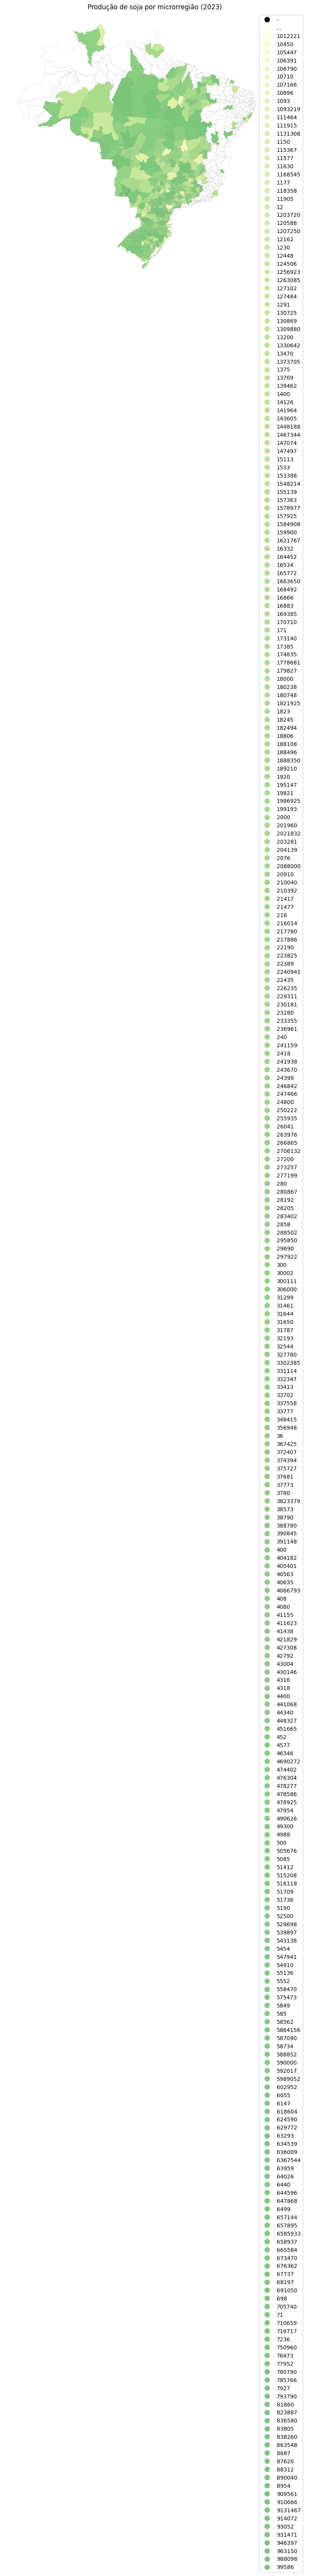

In [10]:
import geobr
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# 1. Geometrias das microrregiões (você já faz isso no seu pipeline)
micro = geobr.read_micro_region(year=2020)

# 2. Agregar produção por microrregião (ex: um ano específico, ou média/soma de vários anos)
producao_ano = df[df['Ano'] == 2023].copy()

# 3. Preparar a chave de join (mesma lógica que você já usa: nome + UF)
producao_ano['chave_join'] = (
    producao_ano['Microrregião Geográfica']
    .str.extract(r'^(.*)\s\((\w+)\)$')
    .apply(lambda x: f"{x[0].lower()}_{x[1].lower()}", axis=1)
)
micro['chave_join'] = (micro['name_micro'] + '_' + micro['abbrev_state']).str.lower()

# 4. Merge geometria + produção
mapa = micro.merge(producao_ano, on='chave_join', how='left')

# 5. Plot
fig, ax = plt.subplots(figsize=(10, 10))
mapa.plot(
    column='Quantidade produzida (Toneladas)',
    cmap='YlGn',
    linewidth=0.1,
    edgecolor='gray',
    legend=True,
    ax=ax,
    missing_kwds={'color': 'lightgrey', 'label': 'Sem produção'},
    norm=mcolors.LogNorm(vmin=1, vmax=mapa['Quantidade produzida (Toneladas)'].max())  # ver nota abaixo
)
ax.set_axis_off()
ax.set_title('Produção de soja por microrregião (2023)')
plt.show()